# Redes Feedforward Profundas: demonstração em NumPy

Este notebook mostra, em código, as ideias centrais do seminário. A rede é escrita em NumPy com o back-propagation **explícito**: nenhuma biblioteca de diferenciação automática é usada no núcleo. O PyTorch aparece só no fim, para conferir os gradientes.

## 0. Configuração

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

np.set_printoptions(precision=4, suppress=True)

AZUL, LARANJA, VERDE_AGUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, GRADE, FUNDO, NEUTRO = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": "#b9b8b3", "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11,
    "legend.frameon": False, "figure.dpi": 110,
})
MAPA_P = LinearSegmentedColormap.from_list("p", [AZUL, NEUTRO, LARANJA])

# Os quatro pontos do XOR (um exemplo por linha) e seus rótulos
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
y = np.array([[0], [1], [1], [0]], float)

## 1. Uma biblioteca mínima: camadas como produtos vetor-Jacobiano

Cada camada implementa dois métodos:

- `forward` calcula a saída e **guarda** o que a volta vai precisar. Isso é o custo de memória do back-propagation.
- `backward` recebe o gradiente na saída, $\boldsymbol G = \nabla_{\text{saída}}J$, e devolve o gradiente na entrada. É um **produto vetor-Jacobiano (VJP)**, calculado sem montar o Jacobiano.

Os exemplos ficam nas **linhas**: $\boldsymbol A = \boldsymbol H\boldsymbol W + \boldsymbol b$. Nessa convenção, as linhas 4 a 6 do Algoritmo 6.4 viram

$$\nabla_{\boldsymbol W}J = \boldsymbol H^\top\boldsymbol G,\qquad \nabla_{\boldsymbol b}J = \textstyle\sum_{\text{exemplos}}\boldsymbol G,\qquad \nabla_{\boldsymbol H}J = \boldsymbol G\,\boldsymbol W^\top.$$

Aqui o `MLP` herda de uma classe `Sequencial`, que também serve para montar redes à mão (seção 9).

In [ ]:
class Linear:
    """Camada afim a = h W + b"""
    def __init__(self, n_in, n_out, rng):
        std = np.sqrt(2.0 / n_in)                  # inicialização He (adequada à ReLU)
        self.W = rng.normal(0, std, (n_in, n_out))
        self.b = np.full(n_out, 0.1)               # viés positivo

    def forward(self, h):
        self.h = h                                 # guarda a entrada para a volta
        return h @ self.W + self.b

    def backward(self, g):                         # g = dJ/da, formato (N, n_out)
        self.dW = self.h.T @ g                     # Alg. 6.4, linha 5
        self.db = g.sum(axis=0)                    # Alg. 6.4, linha 4 (soma no lote)
        return g @ self.W.T                        # Alg. 6.4, linha 6: dJ/dh


class ReLU:
    """g(a) = max(0, a). O Jacobiano é diagonal, então o VJP é g * 1[a > 0]."""
    def forward(self, a):
        self.mask = a > 0
        return a * self.mask

    def backward(self, g):
        return g * self.mask


def sigmoid(z):
    """Sigmoide escrita com tanh: mesmo resultado que 1/(1 + e^-z), mas nunca estoura."""
    return 0.5 * (1 + np.tanh(0.5 * z))


class Sigmoid:
    """Ativação sigmoide; a derivada s(1 - s) é no máximo 1/4"""
    def forward(self, a):
        self.s = sigmoid(a)
        return self.s

    def backward(self, g):
        return g * self.s * (1 - self.s)

In [ ]:
class Sequencial:
    """Cadeia de camadas: a ida em ordem (Alg. 6.3) e a volta em ordem reversa (Alg. 6.4)."""
    def __init__(self, camadas):
        self.layers = list(camadas)

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, g):
        for layer in reversed(self.layers):
            g = layer.backward(g)

    def lineares(self):
        return [L for L in self.layers if isinstance(L, Linear)]


class MLP(Sequencial):
    """MLP totalmente conectado. sizes=[2, 8, 1]: 2 entradas, 8 unidades ocultas e 1 logit de saída."""
    def __init__(self, sizes, seed=0, ativacao=ReLU):
        rng = np.random.default_rng(seed)          # mesma semente, mesmos pesos iniciais
        camadas = []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            camadas += [Linear(n_in, n_out, rng), ativacao()]
        camadas.pop()                              # a saída fica linear: logits
        super().__init__(camadas)

In [ ]:
def bce_with_logits(z, y):
    """Entropia cruzada binária a partir do logit"""
    J = np.mean(np.logaddexp(0, (1 - 2 * y) * z))
    return J, (sigmoid(z) - y) / y.size            # dJ/dz = (previsão - alvo) / N


def mse_sigmoide(z, y):
    """Erro quadrático depois da sigmoide"""
    s = sigmoid(z)
    J = 0.5 * np.mean((s - y) ** 2)
    return J, (s - y) * s * (1 - s) / y.size


def softmax(z):
    z = z - z.max(axis=1, keepdims=True) 
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def softmax_cross_entropy(z, y):
    """Entropia cruzada softmax; y são rótulos inteiros. Gradiente: (q - p) / N."""
    N = z.shape[0]
    zs = z - z.max(axis=1, keepdims=True)
    log_q = zs - np.log(np.exp(zs).sum(axis=1, keepdims=True)) 
    J = -log_q[np.arange(N), y].mean()
    G = np.exp(log_q)
    G[np.arange(N), y] -= 1                        # q - p, com p one-hot
    return J, G / N


def treinar(net, X, y, perda=bce_with_logits, lr=0.1, epocas=2000):
    """Descida de gradiente em lote (todos os exemplos a cada passo). Devolve o custo de cada passo."""
    historico = np.empty(epocas)
    for t in range(epocas):
        J, g = perda(net.forward(X), y)            # ida e gradiente nos logits
        net.backward(g)                            # volta: preenche dW e db
        for L in net.lineares():                   # passo do otimizador
            L.W -= lr * L.dW
            L.b -= lr * L.db
        historico[t] = J
    return historico


def acertos(net, X, y):
    """Número de pontos binários classificados corretamente (limiar 0,5)."""
    return int(((sigmoid(net.forward(X)) > 0.5) == (y > 0.5)).sum())

## 2. XOR: por que o modelo linear falha

O melhor modelo linear, $f(\boldsymbol x) = \boldsymbol x^\top\boldsymbol w + b$, ajustado por mínimos quadrados, ignora a entrada e responde 0,5 em todos os pontos.

In [5]:
A = np.c_[X, np.ones(4)]                           # colunas [x1, x2, 1]
coef, *_ = np.linalg.lstsq(A, y, rcond=None)
print("w =", coef[:2].ravel().round(4) + 0.0, "  b =", coef[2].round(4) + 0.0)
print("previsões do modelo linear:", (A @ coef).ravel().round(4) + 0.0)

w = [0. 0.]   b = [0.5]
previsões do modelo linear: [0.5 0.5 0.5 0.5]


Com uma camada oculta ReLU e os pesos do livro (eqs. 6.4 a 6.6), a rede acerta exatamente. Na convenção por linhas, a matriz do código é a transposta da do livro.

In [6]:
livro = MLP([2, 2, 1])
livro.layers[0].W = np.array([[1., 1.], [1., 1.]]); livro.layers[0].b = np.array([0., -1.])
livro.layers[2].W = np.array([[1.], [-2.]]);         livro.layers[2].b = np.array([0.])

saida = livro.forward(X)
H = livro.layers[1].forward(livro.layers[0].forward(X))   # representação oculta h
print("saída da rede:", saida.ravel())
print("h de cada ponto:\n", H + 0.0)

saída da rede: [0. 1. 1. 0.]
h de cada ponto:
 [[0. 0.]
 [1. 0.]
 [1. 0.]
 [2. 1.]]


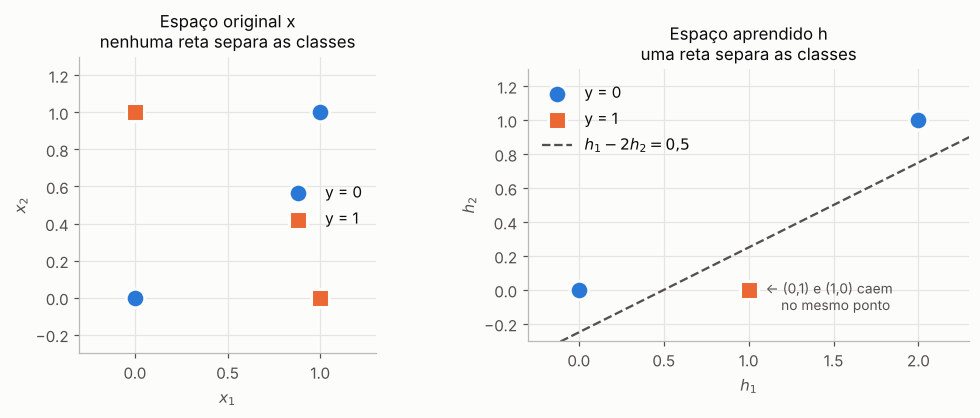

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.9))
paineis = [(axes[0], X, "Espaço original x\nnenhuma reta separa as classes", ("$x_1$", "$x_2$"), (-0.3, 1.3)),
           (axes[1], H, "Espaço aprendido h\numa reta separa as classes", ("$h_1$", "$h_2$"), (-0.3, 2.3))]
for ax, P, titulo, (rx, ry), xlim in paineis:
    for classe, cor, marca, nome in [(0, AZUL, "o", "y = 0"), (1, LARANJA, "s", "y = 1")]:
        sel = y.ravel() == classe
        ax.scatter(P[sel, 0], P[sel, 1], s=150, c=cor, marker=marca,
                   edgecolors=FUNDO, linewidths=2, label=nome, zorder=3)
    ax.set_title(titulo); ax.set_xlabel(rx); ax.set_ylabel(ry)
    ax.set_xlim(*xlim); ax.set_ylim(-0.3, 1.3); ax.set_aspect("equal")
h1 = np.linspace(-0.3, 2.3, 50)
axes[1].plot(h1, (h1 - 0.5) / 2, color=TINTA_2, lw=1.5, ls="--", label="$h_1 - 2h_2 = 0{,}5$")
axes[1].text(1.1, -0.04, "← (0,1) e (1,0) caem\n    no mesmo ponto", color=TINTA_2, fontsize=9, va="center")
axes[0].legend(loc="center right", bbox_to_anchor=(1.0, 0.5)); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

## 3. Treinando o XOR com descida de gradiente

Agora a rede parte de pesos aleatórios: Taxa de aprendizado 0,1 e 2000 passos, usando os 4 pontos a cada passo.

In [8]:
net = MLP([2, 8, 1], seed=0)
hist = treinar(net, X, y)
p = sigmoid(net.forward(X)).ravel()
print("custo final:", round(hist[-1], 4))
print("P(y = 1) em (0,0), (0,1), (1,0), (1,1):", p.round(3))
print("acertos:", acertos(net, X, y), "de 4")

custo final: 0.0101
P(y = 1) em (0,0), (0,1), (1,0), (1,1): [0.002 0.996 0.996 0.03 ]
acertos: 4 de 4


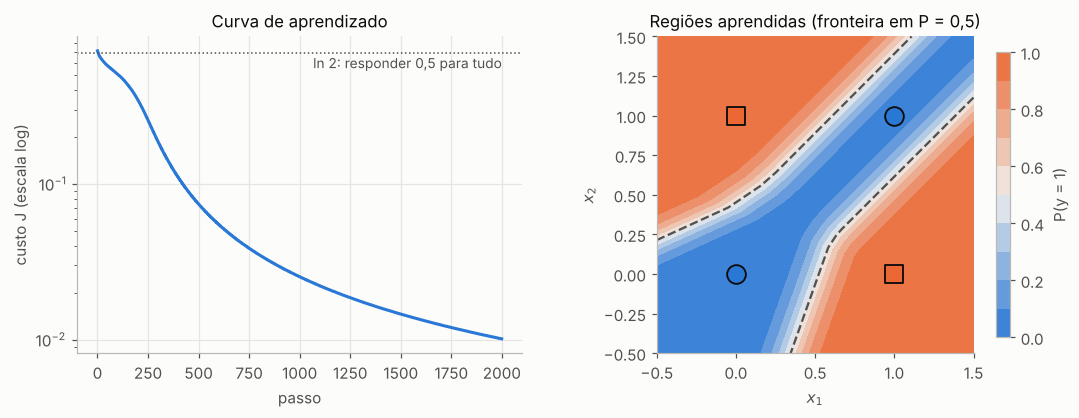

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
ax = axes[0]
ax.plot(hist, color=AZUL)
ax.axhline(np.log(2), color=TINTA_2, lw=1, ls=":")
ax.text(len(hist), np.log(2) * 0.8, "ln 2: responder 0,5 para tudo", ha="right", color=TINTA_2, fontsize=9)
ax.set_yscale("log"); ax.set_xlabel("passo"); ax.set_ylabel("custo J (escala log)")
ax.set_title("Curva de aprendizado")

ax = axes[1]
g1, g2 = np.meshgrid(np.linspace(-0.5, 1.5, 250), np.linspace(-0.5, 1.5, 250))
prob = sigmoid(net.forward(np.c_[g1.ravel(), g2.ravel()])).reshape(g1.shape)
fundo = ax.contourf(g1, g2, prob, levels=np.linspace(0, 1, 11), cmap=MAPA_P)
ax.contour(g1, g2, prob, levels=[0.5], colors=TINTA_2, linewidths=1.5, linestyles="--")
for classe, cor, marca in [(0, AZUL, "o"), (1, LARANJA, "s")]:
    sel = y.ravel() == classe
    ax.scatter(X[sel, 0], X[sel, 1], s=150, c=cor, marker=marca, edgecolors=TINTA, linewidths=1.2, zorder=3)
ax.set_title("Regiões aprendidas (fronteira em P = 0,5)"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_aspect("equal"); ax.grid(False)
fig.colorbar(fundo, ax=ax, label="P(y = 1)", shrink=0.9)
plt.tight_layout(); plt.show()

## 4. O back-prop está certo? Verificação de gradientes

Cada derivada calculada pelo back-prop ($g_{\text{bp}}$) é comparada com a **diferença central**

$$g_{\text{num}} = \frac{J(\theta_i+\epsilon) - J(\theta_i-\epsilon)}{2\epsilon},\qquad \epsilon = 10^{-6},$$

pelo erro relativo $|g_{\text{num}} - g_{\text{bp}}| \,/\, (|g_{\text{num}}| + |g_{\text{bp}}|)$. Abaixo de $10^{-7}$ é excelente; acima de $10^{-2}$, quase certamente haveria um erro no código. Cada linha abaixo testa uma parte diferente da biblioteca.

In [10]:
def grad_check(net, X, y, perda=bce_with_logits, eps=1e-6):
    """Maior erro relativo, entre todos os parâmetros, entre o back-prop e a diferença central."""
    _, g = perda(net.forward(X), y)
    net.backward(g)
    pior = 0.0
    for L in net.lineares():
        for P, dP in [(L.W, L.dW), (L.b, L.db)]:
            for i in np.ndindex(P.shape):
                original = P[i]
                P[i] = original + eps; J_mais, _ = perda(net.forward(X), y)
                P[i] = original - eps; J_menos, _ = perda(net.forward(X), y)
                P[i] = original
                num = (J_mais - J_menos) / (2 * eps)
                pior = max(pior, abs(num - dP[i]) / max(1e-12, abs(num) + abs(dP[i])))
    return pior


rng = np.random.default_rng(42)
X_mc, y_mc = rng.normal(size=(20, 2)), rng.integers(0, 3, size=20)    # dados aleatórios, 3 classes
testes = [
    ("MLP 2-8-1, ReLU, entropia cruzada binária", MLP([2, 8, 1], seed=1), X, y, bce_with_logits),
    ("MLP 2-16-16-1, duas camadas ocultas",       MLP([2, 16, 16, 1], seed=3), X, y, bce_with_logits),
    ("MLP 2-6-6-1, ativação sigmoide",            MLP([2, 6, 6, 1], seed=0, ativacao=Sigmoid), X, y, bce_with_logits),
    ("MLP 2-8-1, MSE depois da sigmoide",         MLP([2, 8, 1], seed=0), X, y, mse_sigmoide),
    ("MLP 2-5-3, softmax + entropia cruzada",     MLP([2, 5, 3], seed=0), X_mc, y_mc, softmax_cross_entropy),
]
for nome, rede, Xt, yt, perda in testes:
    erro = grad_check(rede, Xt, yt, perda)
    assert erro < 1e-5, f"gradiente incorreto em: {nome}"
    print(f"{nome:44s} erro relativo máximo = {erro:.1e}")

MLP 2-8-1, ReLU, entropia cruzada binária    erro relativo máximo = 9.0e-08
MLP 2-16-16-1, duas camadas ocultas          erro relativo máximo = 1.4e-07
MLP 2-6-6-1, ativação sigmoide               erro relativo máximo = 4.4e-07
MLP 2-8-1, MSE depois da sigmoide            erro relativo máximo = 2.7e-09
MLP 2-5-3, softmax + entropia cruzada        erro relativo máximo = 3.9e-09


## 5. Representar ≠ aprender: largura e ReLUs mortas

Com 2 unidades ocultas, a solução exata existe. Mas o treino a encontra? Repetimos o treino da seção 3 com 100 sementes para cada largura $H$.

In [11]:
larguras = [2, 3, 4, 8, 16]
sucessos, redes_h2 = {}, []
inicio = time.time()
for H in larguras:
    sucessos[H] = 0
    for s in range(100):
        n = MLP([2, H, 1], seed=s)
        treinar(n, X, y)
        sucessos[H] += acertos(n, X, y) == 4
        if H == 2:
            redes_h2.append(n)
print(f"500 treinos em {time.time() - inicio:.0f} s")
for H in larguras:
    print(f"H = {H:2d}: {sucessos[H]:3d} de 100 sementes resolvem o XOR")

500 treinos em 30 s
H =  2:  46 de 100 sementes resolvem o XOR
H =  3:  71 de 100 sementes resolvem o XOR
H =  4:  84 de 100 sementes resolvem o XOR
H =  8:  98 de 100 sementes resolvem o XOR
H = 16: 100 de 100 sementes resolvem o XOR


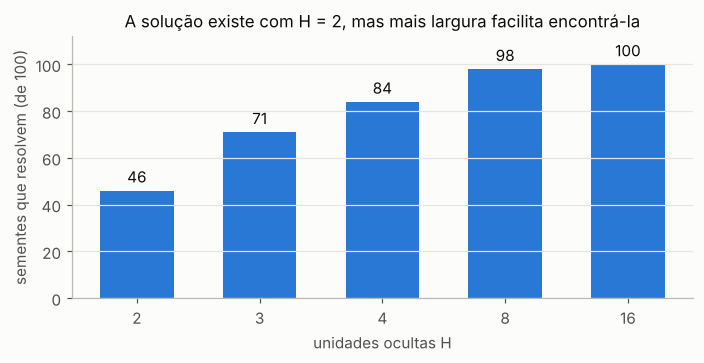

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
barras = ax.bar([str(H) for H in larguras], [sucessos[H] for H in larguras], color=AZUL, width=0.6)
ax.bar_label(barras, padding=3, color=TINTA)
ax.set_ylim(0, 112); ax.set_xlabel("unidades ocultas H"); ax.set_ylabel("sementes que resolvem (de 100)")
ax.set_title("A solução existe com H = 2, mas mais largura facilita encontrá-la")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

Por que tantas falhas com $H = 2$? Uma causa é a **ReLU morta**: uma unidade desligada nos 4 pontos tem gradiente zero para sempre (a máscara bloqueia tudo), e com uma unidade só não dá para resolver o XOR.

In [13]:
falhas = [n for n in redes_h2 if acertos(n, X, y) < 4]           # acertos() roda a ida em X
mortas = [n for n in falhas if np.any(~n.layers[1].mask.any(axis=0))]
print(f"{len(falhas)} falhas com H = 2; em {len(mortas)} delas há ao menos uma ReLU morta")

n = redes_h2[2]                                                  # semente 2
print("\nsemente 2, H = 2: P(y = 1) =", sigmoid(n.forward(X)).ravel().round(3))
print("máscara da ReLU (linhas = pontos, colunas = unidades):\n", n.layers[1].mask)

largo = MLP([2, 8, 1], seed=2)
treinar(largo, X, y)
print("\nmesma semente com H = 8: P(y = 1) =", sigmoid(largo.forward(X)).ravel().round(3))

54 falhas com H = 2; em 21 delas há ao menos uma ReLU morta

semente 2, H = 2: P(y = 1) = [0.334 0.334 0.997 0.334]
máscara da ReLU (linhas = pontos, colunas = unidades):
 [[False False]
 [False False]
 [ True False]
 [False False]]

mesma semente com H = 8: P(y = 1) = [0.004 0.996 0.997 0.005]


A segunda coluna da máscara é toda `False`: essa unidade morreu durante o treino. As falhas restantes ficam presas em mínimos locais, em que a camada oculta não distingue alguns pontos. O custo não é convexo, então a inicialização decide onde o treino termina.

## 6. Entropia cruzada × MSE com saída sigmoide

Para um exemplo com alvo $y = 1$, o gradiente no logit $z$ é

$$\text{entropia cruzada: } \frac{\partial J}{\partial z} = \sigma(z) - 1,\qquad \text{MSE: } \frac{\partial J}{\partial z} = (\sigma(z) - 1)\,\sigma(z)\,(1-\sigma(z)).$$

O fator $\sigma(1-\sigma)$ do MSE vai a zero quando a sigmoide satura, justamente quando a rede está mais errada.

In [14]:
z, alvo = np.array([[-5.0]]), np.array([[1.0]])
print("z = -5, y = 1 (rede muito errada)")
print("  entropia cruzada: dJ/dz =", round(bce_with_logits(z, alvo)[1].item(), 4))
print("  MSE:              dJ/dz =", round(mse_sigmoide(z, alvo)[1].item(), 4))

z = -5, y = 1 (rede muito errada)
  entropia cruzada: dJ/dz = -0.9933
  MSE:              dJ/dz = -0.0066


O efeito no treino: um único neurônio sigmoide começa **confiante e errado** ($w = -6$) num problema de dois pontos. Com o mesmo passo de aprendizado, a entropia cruzada corrige o erro em poucos passos; o MSE fica preso no platô.

entropia cruzada : acerta os dois pontos a partir do passo 7
MSE              : acerta os dois pontos a partir do passo 426


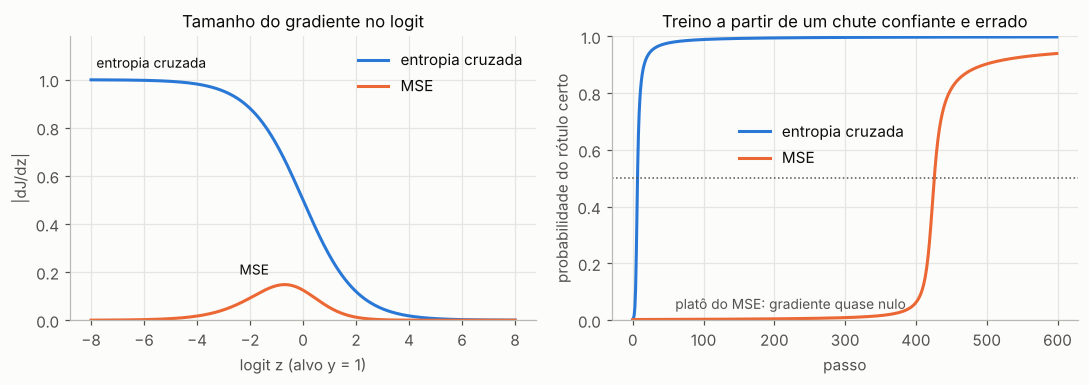

In [15]:
Xs, ys = np.array([[-1.0], [1.0]]), np.array([[0.0], [1.0]])

def prob_certa(perda, passos=600, lr=1.0):
    neuronio = MLP([1, 1]); neuronio.layers[0].W[:] = -6.0; neuronio.layers[0].b[:] = 0.0
    curva = []
    for _ in range(passos):
        q = sigmoid(neuronio.forward(Xs))
        curva.append(np.mean(np.where(ys == 1, q, 1 - q)))   # probabilidade média dada ao rótulo certo
        treinar(neuronio, Xs, ys, perda, lr=lr, epocas=1)
    return np.array(curva)

curvas = {"entropia cruzada": prob_certa(bce_with_logits), "MSE": prob_certa(mse_sigmoide)}
for nome, c in curvas.items():
    print(f"{nome:17s}: acerta os dois pontos a partir do passo {np.argmax(c > 0.5)}")

zz = np.linspace(-8, 8, 400)[:, None]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
s = sigmoid(zz)
ax.plot(zz, np.abs(s - 1), color=AZUL, label="entropia cruzada")
ax.plot(zz, np.abs((s - 1) * s * (1 - s)), color=LARANJA, label="MSE")
ax.text(-7.8, 1.05, "entropia cruzada", color=TINTA, fontsize=9)
ax.text(-2.4, 0.19, "MSE", color=TINTA, fontsize=9)
ax.set_ylim(0, 1.18); ax.legend(loc="upper right")
ax.set_xlabel("logit z (alvo y = 1)"); ax.set_ylabel("|dJ/dz|"); ax.set_title("Tamanho do gradiente no logit")
ax = axes[1]
for (nome, c), cor in zip(curvas.items(), [AZUL, LARANJA]):
    ax.plot(c, color=cor, label=nome)
ax.axhline(0.5, color=TINTA_2, lw=1, ls=":")
ax.set_xlabel("passo"); ax.set_ylabel("probabilidade do rótulo certo"); ax.set_ylim(0, 1)
ax.text(60, 0.04, "platô do MSE: gradiente quase nulo", color=TINTA_2, fontsize=9)
ax.set_title("Treino a partir de um chute confiante e errado")
ax.legend(loc="center", bbox_to_anchor=(0.45, 0.62))
plt.tight_layout(); plt.show()

## 7. Saturação: o gradiente que chega às primeiras camadas

Uma rede com 10 camadas ocultas de 64 unidades, dados aleatórios, **um único** back-prop na inicialização. Medimos a norma do gradiente dos pesos em cada camada. Com sigmoide, cada camada multiplica o sinal por uma derivada de no máximo 1/4, e o gradiente some antes de chegar ao início da rede. A inicialização é a mesma nas duas redes, para a comparação ser justa.

ReLU    : norma na 1ª camada / norma na última = 9.4e-02
sigmoide: norma na 1ª camada / norma na última = 9.1e-07


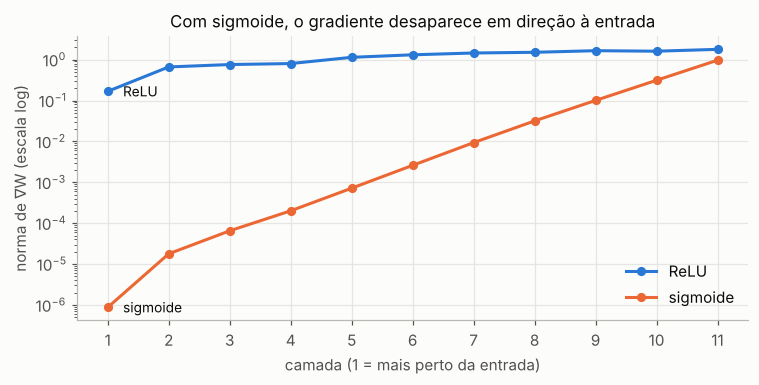

In [16]:
rng = np.random.default_rng(0)
X_prof = rng.normal(size=(256, 10))
y_prof = (rng.random((256, 1)) > 0.5).astype(float)

normas = {}
for nome, ativ in [("ReLU", ReLU), ("sigmoide", Sigmoid)]:
    rede = MLP([10] + [64] * 10 + [1], seed=0, ativacao=ativ)
    _, g = bce_with_logits(rede.forward(X_prof), y_prof)
    rede.backward(g)
    normas[nome] = np.array([np.linalg.norm(L.dW) for L in rede.lineares()])
    print(f"{nome:8s}: norma na 1ª camada / norma na última = {normas[nome][0] / normas[nome][-1]:.1e}")

camadas = np.arange(1, 12)
fig, ax = plt.subplots(figsize=(7, 3.6))
for (nome, v), cor in zip(normas.items(), [AZUL, LARANJA]):
    ax.plot(camadas, v, color=cor, marker="o", markersize=5, label=nome)
    ax.text(1.25, v[0], nome, color=TINTA, va="center", fontsize=9)
ax.set_yscale("log"); ax.set_xlim(0.5, 11.5); ax.set_xticks(camadas); ax.legend(loc="lower right")
ax.set_xlabel("camada (1 = mais perto da entrada)"); ax.set_ylabel("norma de ∇W (escala log)")
ax.set_title("Com sigmoide, o gradiente desaparece em direção à entrada")
plt.tight_layout(); plt.show()

## 8. Saída softmax: três espirais

Somar uma constante a todos os logits não muda o softmax, então subtraímos o maior antes de exponenciar.

In [17]:
z_grande = np.array([[1000.0, 999.0]])
with np.errstate(over="ignore", invalid="ignore"):
    ingenuo = np.exp(z_grande) / np.exp(z_grande).sum()
print("softmax ingênuo: ", ingenuo.ravel(), " (e^1000 estoura)")
print("softmax estável: ", softmax(z_grande).ravel().round(3))

softmax ingênuo:  [nan nan]  (e^1000 estoura)
softmax estável:  [0.731 0.269]


Agora um problema de três classes que nenhuma reta resolve. Comparamos um modelo linear com softmax (`MLP([2, 3])`, sem camada oculta) e um MLP com duas camadas ocultas de 64 unidades. O custo e o otimizador são os mesmos.

In [18]:
def espirais(n=100, classes=3, ruido=0.2, seed=0):
    """Três espirais entrelaçadas no plano, n pontos por classe."""
    rng = np.random.default_rng(seed)
    X, y = np.zeros((n * classes, 2)), np.zeros(n * classes, int)
    for c in range(classes):
        r = np.linspace(0.0, 1.0, n)
        t = np.linspace(4 * c, 4 * (c + 1), n) + rng.normal(0, ruido, n)
        X[c * n:(c + 1) * n] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[c * n:(c + 1) * n] = c
    return X, y

X_esp, y_esp = espirais()
modelos = {"linear + softmax": MLP([2, 3], seed=0), "MLP 2-64-64-3": MLP([2, 64, 64, 3], seed=0)}
for nome, m in modelos.items():
    inicio = time.time()
    h = treinar(m, X_esp, y_esp, softmax_cross_entropy, lr=1.0, epocas=3000)
    acc = np.mean(m.forward(X_esp).argmax(axis=1) == y_esp)
    print(f"{nome:17s}: custo final {h[-1]:.3f}, acurácia de treino {acc:.1%} ({time.time() - inicio:.1f} s)")

linear + softmax : custo final 0.733, acurácia de treino 54.0% (0.2 s)


MLP 2-64-64-3    : custo final 0.021, acurácia de treino 99.3% (1.5 s)


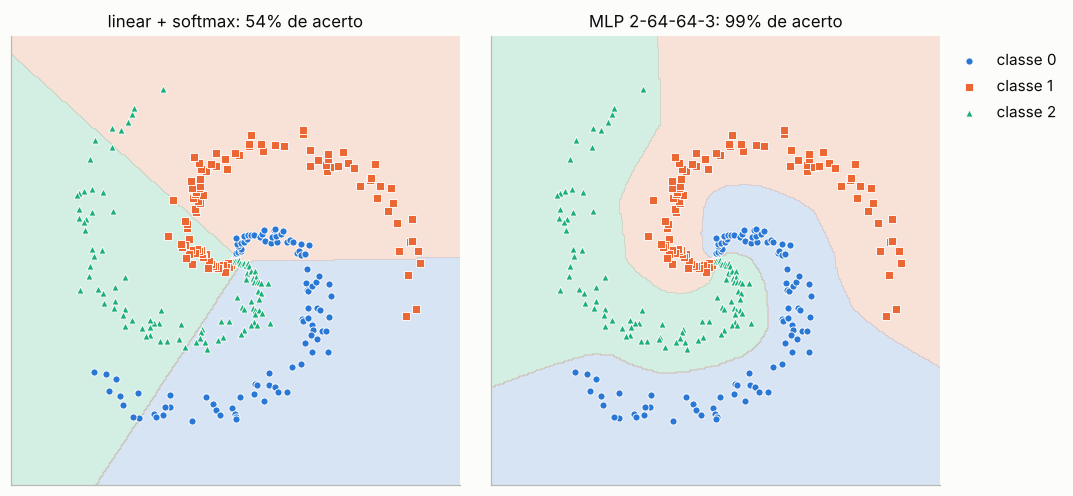

In [19]:
cores, marcas = [AZUL, LARANJA, VERDE_AGUA], ["o", "s", "^"]
g1, g2 = np.meshgrid(np.linspace(-1.2, 1.2, 300), np.linspace(-1.2, 1.2, 300))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (nome, m) in zip(axes, modelos.items()):
    regiao = m.forward(np.c_[g1.ravel(), g2.ravel()]).argmax(axis=1).reshape(g1.shape)
    ax.contourf(g1, g2, regiao, levels=[-0.5, 0.5, 1.5, 2.5], colors=cores, alpha=0.18)
    for c in range(3):
        sel = y_esp == c
        ax.scatter(X_esp[sel, 0], X_esp[sel, 1], s=22, c=cores[c], marker=marcas[c],
                   edgecolors=FUNDO, linewidths=0.6, label=f"classe {c}")
    acc = np.mean(m.forward(X_esp).argmax(axis=1) == y_esp)
    ax.set_title(f"{nome}: {acc:.0%} de acerto"); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.show()

## 9. Profundidade: as dobras de Telgarsky

A função $T(x) = 2\,\mathrm{relu}(x) - 4\,\mathrm{relu}(x - \tfrac12)$ dobra o intervalo $[0, 1]$ ao meio. Ela é feita com 2 ReLUs, e montamos cada dobra com as próprias camadas `Linear` e `ReLU` da biblioteca. Compor $L$ dobras dá $2^L$ pedaços lineares usando só $2L$ unidades. Uma rede com uma única camada de $N$ ReLUs tem no máximo $N + 1$ pedaços.

In [20]:
def dobra():
    """Três camadas que implementam T(x) = 2 relu(x) - 4 relu(x - 1/2)."""
    rng = np.random.default_rng(0)                 # os pesos são sobrescritos abaixo
    entrada, saida = Linear(1, 2, rng), Linear(2, 1, rng)
    entrada.W, entrada.b = np.array([[1.0, 1.0]]), np.array([0.0, -0.5])
    saida.W, saida.b = np.array([[2.0], [-4.0]]), np.array([0.0])
    return [entrada, ReLU(), saida]


def rede_de_dobras(L):
    return Sequencial([camada for _ in range(L) for camada in dobra()])


def conta_pedacos(rede, n=2**14 + 1):
    """Conta os trechos lineares em [0, 1] pelas mudanças de inclinação."""
    x = np.linspace(0, 1, n)[:, None]
    inclinacao = np.diff(rede.forward(x).ravel()) / np.diff(x.ravel())
    return 1 + int(np.sum(np.abs(np.diff(inclinacao)) > 1e-6 * np.abs(inclinacao).max()))


print(" L | pedaços | ReLUs na rede profunda | ReLUs mínimas numa camada só")
for L in range(1, 11):
    print(f"{L:2d} | {conta_pedacos(rede_de_dobras(L)):7d} | {2 * L:22d} | {2**L - 1:28d}")

 L | pedaços | ReLUs na rede profunda | ReLUs mínimas numa camada só
 1 |       2 |                      2 |                            1
 2 |       4 |                      4 |                            3
 3 |       8 |                      6 |                            7
 4 |      16 |                      8 |                           15
 5 |      32 |                     10 |                           31
 6 |      64 |                     12 |                           63
 7 |     128 |                     14 |                          127
 8 |     256 |                     16 |                          255
 9 |     512 |                     18 |                          511
10 |    1024 |                     20 |                         1023


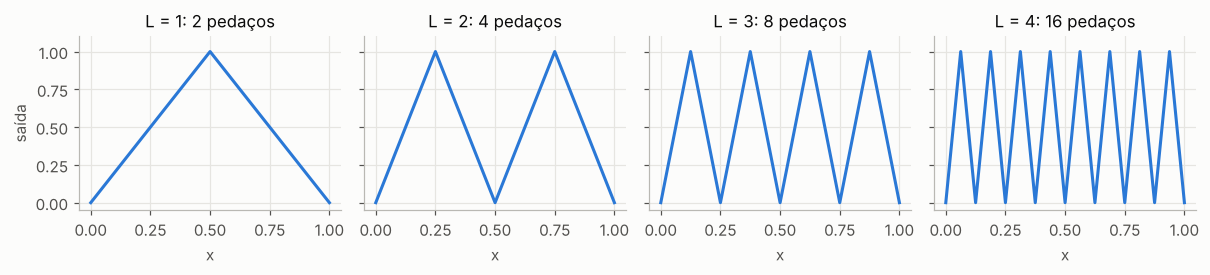

In [21]:
x = np.linspace(0, 1, 2001)[:, None]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), sharey=True)
for ax, L in zip(axes, [1, 2, 3, 4]):
    ax.plot(x, rede_de_dobras(L).forward(x), color=AZUL)
    ax.set_title(f"L = {L}: {2**L} pedaços"); ax.set_xlabel("x"); ax.set_ylim(-0.05, 1.1)
axes[0].set_ylabel("saída")
plt.tight_layout(); plt.show()

## 10. Conferência com o PyTorch

O mesmo MLP, os mesmos pesos e o mesmo custo, agora com o `autograd` do PyTorch.

In [ ]:
try:
    import torch
except ImportError:
    torch = None
    print("PyTorch não está instalado: esta seção é opcional e foi pulada.")

if torch is not None:
    rede = MLP([2, 8, 1], seed=0)
    _, g = bce_with_logits(rede.forward(X), y)
    rede.backward(g)

    W1, b1, W2, b2 = [torch.tensor(a, requires_grad=True)
                      for L in rede.lineares() for a in (L.W, L.b)]
    z = torch.relu(torch.tensor(X) @ W1 + b1) @ W2 + b2
    J = torch.nn.functional.binary_cross_entropy_with_logits(z, torch.tensor(y))
    J.backward()

    nossos = [a for L in rede.lineares() for a in (L.dW, L.db)]
    print(f"PyTorch {torch.__version__}")
    for nome, t, nosso in zip(["W1", "b1", "W2", "b2"], [W1, b1, W2, b2], nossos):
        print(f"  {nome}: maior diferença = {np.abs(t.grad.numpy() - nosso).max():.1e}")

PyTorch 2.15.0+cu132
  W1: maior diferença = 0.0e+00
  b1: maior diferença = 0.0e+00
  W2: maior diferença = 0.0e+00
  b2: maior diferença = 0.0e+00
